# Traveling-wave MZM: reference-model validation

We will reproduce the voltage-integration response, fit it with Circulax, and build an equivalent RLC circuit. Then we will compare their 56 Gbaud eye diagrams.

The line and junction parameters come from `circuit_mzm_rf_transmission_line_skrf.ipynb`. Use the Circulax development checkout containing `rlgc_transmission_line`; its dependencies include scikit-rf, SciPy and Matplotlib.

For a native optical-field simulation with delayed PN-junction phase shifters, see [the companion notebook](traveling_wave_mzm.ipynb).

This advanced notebook compares modeling methods. Start with [the push-pull MZM tutorial](traveling_wave_mzm_reference.ipynb) to build and simulate the circuit.

In [1]:
from pathlib import Path

import jax
import jax.numpy as jnp
import matplotlib.pyplot as plt
import numpy as np
from scipy.constants import speed_of_light as c
from traveling_wave_mzm_models import rlc_netlist, voltage_integration_reference

from circulax import compile_circuit
from circulax.components import rlgc_transmission_line
from circulax.components.electronic import WAVE_PWL, Capacitor, Inductor, Resistor, WaveformVoltageSource
from circulax.fitting import ModelFitOptions, circuit_from_coefficients, fit_model, validate_model

jax.config.update("jax_enable_x64", True)
plt.rcParams.update({"figure.figsize": (10, 3.5), "axes.grid": True})
n_sections, dz = 10, 200e-6
length_m = n_sections * dz
z_ref, z_line, n_opt = 30.0, 60.0, 4.05
rj_product, cj_per_m = 4.7e-3, 320e-12
v_bias, source_vpp = -1.0, 4.0
phase_a1, phase_a2 = 1.2, 0.15  # rad/(V mm), rad/(V^2 mm)
length_mm = length_m * 1e3
# Fit through 160 GHz to cover the NRZ edge spectrum; display the original 0-40 GHz band.
frequencies = np.unique(np.r_[0.0, np.geomspace(1e3, 1e9, 81), np.linspace(1e9, 160e9, 801)])
s = 2j * np.pi * frequencies
original_band = frequencies <= 40e9
data_dir = Path("data")
data_dir.mkdir(exist_ok=True)

## 1. Voltage-integration reference

Each 200 µm section contains half a transmission line, a 23.5 Ω / 64 fF junction, then another half-line. The junction voltages are averaged with optical walk-off:

$$H_\mathrm{avg}(s)=\frac1N\sum_k\frac{V_{j,k}}{V_s}e^{-s(N-k)\Delta z n_g/c}.$$

Scikit-rf’s `Network.a` converts the half-line S-parameters to ABCD matrices. The function below uses these to calculate the junction voltages; the full four-port builder is in the accompanying `traveling_wave_mzm_models.py`. The four ports are RF in, integration in, RF out and integrated-voltage out. With 30 Ω matched RF source/load, $S_{41}=2H_\mathrm{avg}$.

We retain the original integration input's 50 Ω impedance and use a matched output buffer. Its gain of 2 preserves the original delivered voltage into 30 Ω while allowing a finite state-space realization.

In [2]:
def h_local(half, z_ref=z_ref, rj_product=rj_product, cj_per_m=cj_per_m):
    sh = np.zeros_like(half)
    sh[:, 0, 0] = sh[:, 1, 1] = 1
    sh[:, 1, 0] = s * (cj_per_m * dz) / (1 + s * (rj_product / dz) * (cj_per_m * dz))
    unit = half @ sh @ half
    total = np.linalg.matrix_power(unit, n_sections)
    hv = 1 / (total[:, 0, 0] + total[:, 0, 1] / z_ref + z_ref * (total[:, 1, 0] + total[:, 1, 1] / z_ref))
    state = np.column_stack([hv, hv / z_ref])
    vjs = np.zeros((len(frequencies), n_sections), complex)
    for k in range(n_sections - 1, -1, -1):
        state = np.einsum("fij,fj->fi", half, state)
        vjs[:, k] = state[:, 0] / (1 + s * (rj_product / dz) * (cj_per_m * dz))
        state = np.einsum("fij,fj->fi", sh, state)
        state = np.einsum("fij,fj->fi", half, state)
    hvint = np.mean(vjs * np.exp(-s[:, None] * np.arange(n_sections, 0, -1)[None, :] * dz * n_opt / c), axis=1)
    return hv, hvint, vjs

In [3]:
medium, reference = voltage_integration_reference(
    frequencies,
    n_sections=n_sections,
    dz=dz,
    z_line=z_line,
    z_ref=z_ref,
    n_opt=n_opt,
    rj_product=rj_product,
    cj_per_m=cj_per_m,
    ep_r=4.04,
    tanD=0.11,
    A=0.0009,
)
gamma = np.asarray(medium.gamma)
reference.name = "traveling_wave_mzm_voltage_integration"
reference.write_touchstone(filename=str(data_dir / reference.name))

## 2. Fit a transient-capable model

Fit all four ports from 1 kHz to 160 GHz, reserving every fifth sample for validation. Check DC separately. The controlled-source monitor makes this an active, nonreciprocal network, so reciprocal fitting and passivity enforcement are disabled.

In [4]:
training = np.arange(len(frequencies)) % 5 != 0
options = ModelFitOptions(
    method="vector_fitting",
    vector_fit_order=(2, 8),
    reciprocal=False,
    normalized_rmse=0.005,
    max_absolute_error=0.01,
)
fit_coeffs = fit_model(reference.s[training], frequencies[training], z0=z_ref, options=options)
report = validate_model(
    fit_coeffs,
    measured_S=reference.s[training],
    freqs=frequencies[training],
    validation_S=reference.s[~training],
    validation_freqs=frequencies[~training],
    expected_passive=False,
    expected_reciprocal=False,
    normalized_rmse=0.005,
    max_absolute_error=0.01,
)
report.raise_for_simulation()
print(f"Held-out fit error: {report.validation_nrmse:.3%} NRMSE")
assert np.max(np.abs(fit_coeffs.evaluate([0.0])[0] - reference.s[0])) < 0.01
fit_coeffs.save(data_dir / "traveling_wave_mzm_reference_fit.npz")
fitted_network = circuit_from_coefficients(fit_coeffs, name="VoltageIntegrationReference")
# Check the actual S-to-Y/state-space circuit, not only pole-residue evaluation.
check_freqs = jnp.asarray(frequencies[::8])
realized_s = np.asarray(fitted_network.sp(ports=["p1", "p2", "p3", "p4"], freqs=check_freqs, z0=z_ref))
realization_error = np.max(np.abs(realized_s - fit_coeffs.evaluate(np.asarray(check_freqs))))
assert realization_error < 1e-5

Held-out fit error: 0.235% NRMSE


## 3. Reconstruct the line with RLC components

A fixed RLC section cannot reproduce frequency-dependent loss. We approximate it with several ordinary RLC branches, each with a different time constant.

For this reference, the characteristic impedance $Z_c$ is a constant real number, so the series impedance and shunt admittance per metre are

$$Z'(s)=Z_c\gamma(s),\qquad Y'(s)=\gamma(s)/Z_c,\qquad s=j2\pi f.$$

We fit $\gamma$ as a sum of simple functions:

$$\hat\gamma(s)=g_0+s\ell_\infty+\sum_q w_q\frac{s}{s+p_q}.$$

The positive rates $p_q$ are chosen on a logarithmic grid; $1/p_q$ is a branch time constant. Only $g_0$, $\ell_\infty$ and the weights $w_q$ are fitted. The factory below uses nonnegative least squares (`scipy.optimize.nnls`) to match the real and imaginary parts. Relative weighting, capped near zero, prevents the largest responses from dominating.

The reusable factory fits $Z'=R+sL$ and $Y'=G+sC$ independently using this same form, so it also supports frequency-dependent characteristic impedance. Its `series` and `shunt` fields expose the fitted constant, linear coefficient, weights and pole rates.

Factory fit NRMSE: series 0.620%, shunt 0.620%


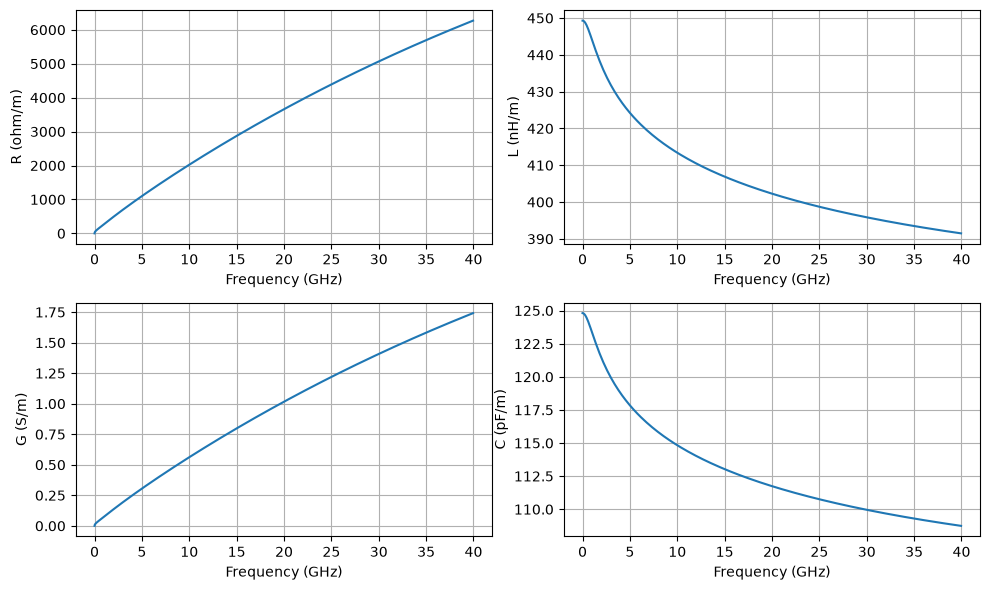

In [5]:
z_per_m, y_per_m = z_line * gamma, gamma / z_line
omega = 2 * np.pi * frequencies
r_per_m, g_per_m = z_per_m.real, y_per_m.real
l_per_m = np.divide(z_per_m.imag, omega, out=np.zeros_like(omega), where=omega > 0)
c_per_m = np.divide(y_per_m.imag, omega, out=np.zeros_like(omega), where=omega > 0)
n_dc = np.sqrt(np.real(medium.ep_r_f[0]))
l_per_m[0], c_per_m[0] = z_line * n_dc / c, n_dc / (z_line * c)
# Choose branch time constants, then fit their nonnegative strengths.
foster_poles = 2 * np.pi * np.geomspace(1e8, 2e12, 12)
# Reusable factory: fit RLGC per metre once, then choose lengths and section counts.
line = rlgc_transmission_line(frequencies, R=r_per_m, L=l_per_m, G=g_per_m, C=c_per_m, poles=foster_poles)
print(f"Factory fit NRMSE: series {line.series.normalized_rmse:.3%}, shunt {line.shunt.normalized_rmse:.3%}")
np.savez(
    data_dir / "traveling_wave_mzm_rlgc.npz",
    frequency_hz=frequencies,
    R_ohm_per_m=r_per_m,
    L_H_per_m=l_per_m,
    G_S_per_m=g_per_m,
    C_F_per_m=c_per_m,
    series_constant=line.series.constant,
    series_linear=line.series.linear,
    series_weights=line.series.weights,
    series_poles_rad_s=line.series.poles,
    shunt_constant=line.shunt.constant,
    shunt_linear=line.shunt.linear,
    shunt_weights=line.shunt.weights,
    shunt_poles_rad_s=line.shunt.poles,
)
fig, axes = plt.subplots(2, 2, figsize=(10, 6))
for ax, values, label, multiplier in zip(
    axes.flat,
    (r_per_m, l_per_m, g_per_m, c_per_m),
    ("R (ohm/m)", "L (nH/m)", "G (S/m)", "C (pF/m)"),
    (1, 1e9, 1, 1e12),
    strict=True,
):
    ax.plot(frequencies[original_band] / 1e9, values[original_band] * multiplier)
    ax.set(xlabel="Frequency (GHz)", ylabel=label)
plt.tight_layout()
plt.show()

### Turn each fitted term into components

For a line slice of length $d$, use $Z_\mathrm{series}=dZ_c\hat\gamma$ and $Y_\mathrm{shunt}=d\hat\gamma/Z_c$. The constant and linear terms give

| Term in $\hat\gamma$ | Series path | Shunt path to ground |
| --- | --- | --- |
| $g_0$ | $R_0=dZ_cg_0$ | $G_0=dg_0/Z_c$, implemented as $R=1/G_0$ |
| $s\ell_\infty$ | $L_\infty=dZ_c\ell_\infty$ | $C_\infty=d\ell_\infty/Z_c$ |

For a rational term, set $a=dZ_cw_q$. A **parallel R–L pair** has impedance

$$Z_{R\parallel L}=\frac{R\,sL}{R+sL}=a\frac{s}{s+p_q}
\quad\text{when}\quad R=a,\ L=a/p_q.$$

Set $b=dw_q/Z_c$. A **series R–C pair** has admittance

$$Y_{R+C}=\frac{1}{R+1/(sC)}=b\frac{s}{s+p_q}
\quad\text{when}\quad R=1/b,\ C=b/p_q.$$

Connect the R–L pairs **in series along the line**; connect the R–C pairs **in parallel to ground**. Their impedances or admittances then add, reproducing the fitted sum. Nonnegative coefficients give passive elements, and $p_q>0$ gives stable branch poles. Terms with zero weight can be omitted.

The code below converts one fitted branch and checks these identities. These are the same formulas used by the line factory; no S-parameter-to-state-space conversion is involved.

In [6]:
d = dz / 2  # One half-section of line, in metres.
r0, l_inf = d * line.series.constant, d * line.series.linear
g_shunt, c_inf = d * line.shunt.constant, d * line.shunt.linear

# Show one active branch from each fit; the builder repeats these for all weights.
a, p_series = d * line.series.weights[0], line.series.poles[0]
b, p_shunt = d * line.shunt.weights[0], line.shunt.poles[0]
r_series, l_series = a, a / p_series  # R || L, inserted along the line.
r_shunt, c_shunt = 1 / b, b / p_shunt  # R + C, connected to ground.

z_parallel_rl = r_series * (s * l_series) / (r_series + s * l_series)
y_series_rc = s * c_shunt / (1 + s * r_shunt * c_shunt)
np.testing.assert_allclose(z_parallel_rl, a * s / (s + p_series), atol=1e-12)
np.testing.assert_allclose(y_series_rc, b * s / (s + p_shunt), atol=1e-12)
print(f"Base series: R = {r0:.3g} ohm, L = {l_inf * 1e12:.3g} pH")
print(f"Base shunt: G = {g_shunt:.3g} S, C = {c_inf * 1e15:.3g} fF")
print(f"First series branch: R || L = {r_series:.3g} ohm || {l_series * 1e12:.3g} pH")
print(f"First shunt branch: R + C = {r_shunt:.3g} ohm + {c_shunt * 1e15:.3g} fF")

Base series: R = 0.00146 ohm, L = 31.7 pH
Base shunt: G = 4.04e-07 S, C = 8.81 fF
First series branch: R || L = 0.0118 ohm || 18.8 pH
First shunt branch: R + C = 3.04e+05 ohm + 5.23 fF


### Compare the AC response

Approximate each half-section by a symmetric T network: half the series impedance, the full shunt admittance, then half the series impedance. In the formulas above, use `d / 2` for each series arm and `d` for the shunt. `rlc_netlist` expands it into Circulax resistors, inductors and capacitors, including the junction loading. Compare the resulting EE and voltage-integration responses with the reference and vector fit.

`rlgc_transmission_line` accepts scalar or sampled RLGC values per metre and fits series impedance and shunt admittance independently. Calling `line(length=..., n_sections=...)` creates a connectable Circulax RLC circuit; fitting is reused across lengths. The default fit tolerance is 1% weighted RMS per response; inspect `line.series` and `line.shunt` for coefficients and errors. This branch family is an approximation, and spatial convergence must be checked separately.

In [7]:
def direct_half_line(subdivisions=1, line=line):
    d = dz / (2 * subdivisions)
    series = np.tile(np.eye(2, dtype=complex), (len(frequencies), 1, 1))
    shunt = series.copy()
    series[:, 0, 1] = line.series.evaluate(frequencies) * d / 2
    shunt[:, 1, 0] = line.shunt.evaluate(frequencies) * d
    return np.linalg.matrix_power(series @ shunt @ series, subdivisions)


h_ee, h_avg, _ = h_local(medium.line(d=dz / 2, unit="m").a)
direct_results = {1: h_local(direct_half_line())}
np.testing.assert_allclose(2 * h_ee, reference.s[:, 2, 0], atol=1e-6)
np.testing.assert_allclose(2 * h_avg, reference.s[:, 3, 0], atol=1e-6)

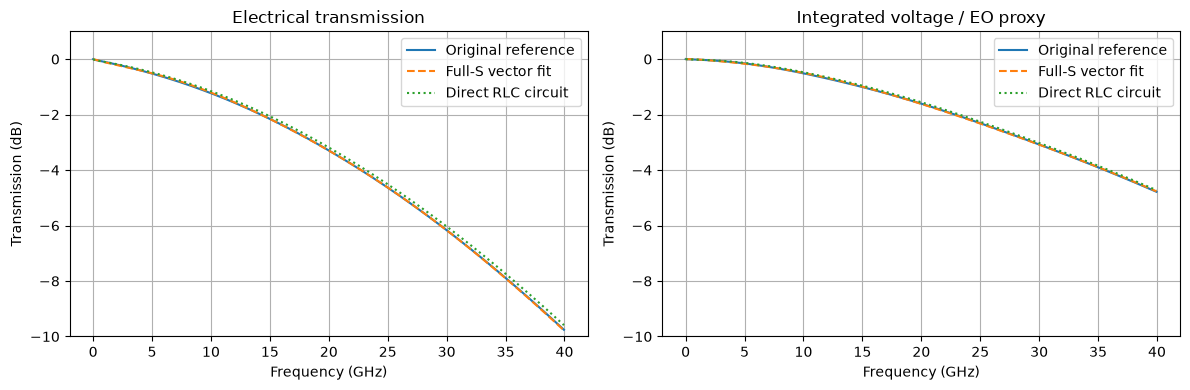

Maximum EO magnitude error: 0.058 dB over 0-40 GHz


In [8]:
rlc_models = {"R": Resistor, "L": Inductor, "C": Capacitor, "drive": WaveformVoltageSource, "line": line(length=dz / 2)}
ladder_net = rlc_netlist(
    n_sections=n_sections,
    dz=dz,
    z_ref=z_ref,
    rj_product=rj_product,
    cj_per_m=cj_per_m,
    v_bias=v_bias,
)
ladder = compile_circuit(ladder_net, rlc_models, is_complex=False, g_leak=0)
# Spot-check the component circuit; use its ABCD equivalent for the smooth curves.
ac_indices = np.array([np.argmin(abs(frequencies - 20e9))])
ladder_ac = ladder.ac_response(freqs=jnp.asarray(frequencies[ac_indices]), sources={"VS": 1.0})
native_junction = np.stack([np.asarray(ladder.port(ladder_ac["solution"], f"junction_{k}")) for k in range(n_sections)], axis=1)
native_ee = np.asarray(ladder.port(ladder_ac["solution"], "rf_output"))
np.testing.assert_allclose(native_ee, direct_results[1][0][ac_indices], rtol=1e-7, atol=1e-8)
np.testing.assert_allclose(native_junction, direct_results[1][2][ac_indices], rtol=1e-7, atol=1e-8)
fitted_s = fit_coeffs.evaluate(frequencies)
fig, axes = plt.subplots(1, 2, figsize=(12, 4))
for ax, row, direct_h, title in zip(
    axes, (2, 3), direct_results[1][:2], ("Electrical transmission", "Integrated voltage / EO proxy"), strict=True
):
    for response, label, style in (
        (reference.s[:, row, 0], "Original reference", "-"),
        (fitted_s[:, row, 0], "Full-S vector fit", "--"),
        (2 * direct_h, "Direct RLC circuit", ":"),
    ):
        ax.plot(frequencies[original_band] / 1e9, 20 * np.log10(abs(response[original_band])), style, label=label)
    ax.set(xlabel="Frequency (GHz)", ylabel="Transmission (dB)", title=title, ylim=(-10, 1))
    ax.legend()
plt.tight_layout()
plt.show()
assert np.max(abs(2 * direct_results[1][1][original_band] - reference.s[original_band, 3, 0])) < 0.01
eo_error_db = np.max(abs(20 * np.log10(abs(direct_results[1][1][original_band] / h_avg[original_band]))))
print(f"Maximum EO magnitude error: {eo_error_db:.3f} dB over 0-40 GHz")

## 4. Drive both circuits at 56 Gbaud

Use the same finite-rise NRZ sequence, 30 Ω source/load and constant prehistory. The fitted circuit produces the integrated voltage directly. For the RLC circuit, save the local junction voltages, apply the optical delays, and average them.

In [9]:
baud = 56e9
ui, samples_per_ui = 1 / baud, 32
sample_dt = ui / samples_per_ui
rng = np.random.default_rng(56)
preamble_bits = 16
bits = np.r_[np.ones(preamble_bits), rng.integers(0, 2, 96)]
levels = 2 * v_bias + source_vpp * (bits - 0.5)
pwl_t, pwl_v = [0.0], [float(levels[0])]
for k in range(1, len(bits)):
    if levels[k] != levels[k - 1]:
        pwl_t.extend([k * ui, (k + 0.2) * ui])
        pwl_v.extend([float(levels[k - 1]), float(levels[k])])
t_stop = len(bits) * ui
pwl_t.append(t_stop)
pwl_v.append(float(levels[-1]))
drive = {"kind": WAVE_PWL, "pwl_t": jnp.asarray(pwl_t), "pwl_v": jnp.asarray(pwl_v)}
ladder_net["instances"]["VS"]["settings"] = drive
ladder = compile_circuit(ladder_net, rlc_models, is_complex=False, g_leak=0)
fit_net = {
    "instances": {
        "GND": {"component": "ground"},
        "VS": {"component": "drive", "settings": drive},
        "RS": {"component": "R", "settings": {"R": z_ref}},
        "FIT": {"component": "fitted"},
        **{f"LOAD{i}": {"component": "R", "settings": {"R": z_ref}} for i in (2, 3, 4)},
    },
    "connections": {
        "GND,p1": ("VS,p2", "LOAD2,p2", "LOAD3,p2", "LOAD4,p2"),
        "VS,p1": "RS,p1",
        "RS,p2": "FIT,p1",
        **{f"FIT,p{i}": f"LOAD{i},p1" for i in (2, 3, 4)},
    },
    "ports": {"rf_output": "FIT,p3", "integrated_voltage": "FIT,p4"},
}
fitted_electrical = compile_circuit(
    fit_net, {"R": Resistor, "drive": WaveformVoltageSource, "fitted": fitted_network}, is_complex=True, g_leak=0
)
sample_times = jnp.arange(len(bits) * samples_per_ui + 1) * sample_dt


def simulate(circuit):
    sol = circuit.transient(
        t0=0.0, t1=t_stop, dt0=sample_dt / 4, saveat=sample_times, max_steps=4 * len(bits) * samples_per_ui + 20, throw=True
    )
    sol.ys.block_until_ready()
    return sol


fit_sol = simulate(fitted_electrical)
rlc_sol = simulate(ladder)
v_integrated_fit = np.asarray(fitted_electrical.port(fit_sol.ys, "integrated_voltage")).real
junction_t = np.stack([np.asarray(ladder.port(rlc_sol.ys, f"junction_{k}")).real for k in range(n_sections)], axis=1)
monitor_delays = np.arange(n_sections, 0, -1) * dz * n_opt / c
retarded_junction = np.column_stack(
    [np.interp(np.asarray(sample_times) - monitor_delays[k], np.asarray(sample_times), junction_t[:, k]) for k in range(n_sections)]
)
v_integrated_direct = retarded_junction.mean(axis=1)

Integrated-voltage RMS difference: 0.004144 V


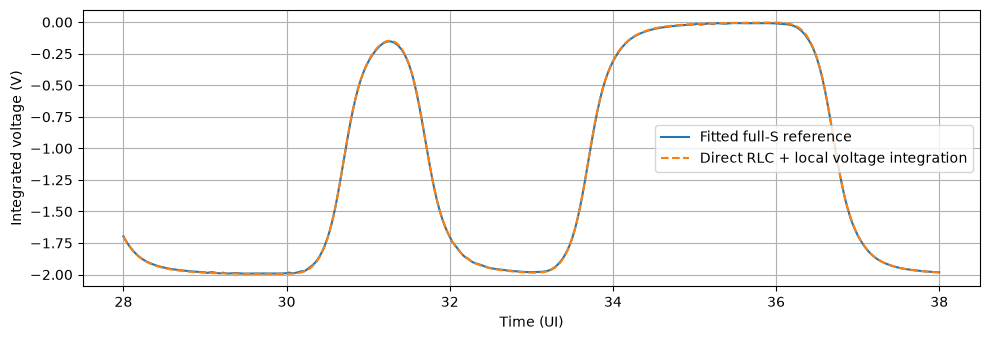

In [10]:
settled = np.asarray(sample_times) > (preamble_bits + 8) * ui
print(
    f"Integrated-voltage RMS difference: {np.sqrt(np.mean((v_integrated_fit[settled] - v_integrated_direct[settled]) ** 2)):.4g} V"
)
fig, ax = plt.subplots()
mask = (np.asarray(sample_times) / ui >= preamble_bits + 12) & (np.asarray(sample_times) / ui <= preamble_bits + 22)
ax.plot(np.asarray(sample_times)[mask] / ui, v_integrated_fit[mask], label="Fitted full-S reference")
ax.plot(np.asarray(sample_times)[mask] / ui, v_integrated_direct[mask], "--", label="Direct RLC + local voltage integration")
ax.set(xlabel="Time (UI)", ylabel="Integrated voltage (V)")
ax.legend()
plt.tight_layout()
plt.show()

## 5. Apply the quadratic phase law

Compare one phase shifter driven by the integrated voltage with a quadratic phase shift applied at each section. Averaging and squaring do not generally commute:

$$\phi_\mathrm{local}-\phi_\mathrm{lumped}=L_\mathrm{mm}a_2\operatorname{Var}(V_j).$$

Evaluate the matched-arm MZM output as $P/P_\mathrm{through}=[1+\sin\phi]/2$. Here optical phase is calculated from the saved voltage histories; the companion notebook demonstrates the native delayed optical-field component. All three eyes use the original monitor-chain delay convention, which adds half a section of common latency relative to the physical midpoint model.

Peak local-vs-lumped quadratic phase difference: 0.0190 rad


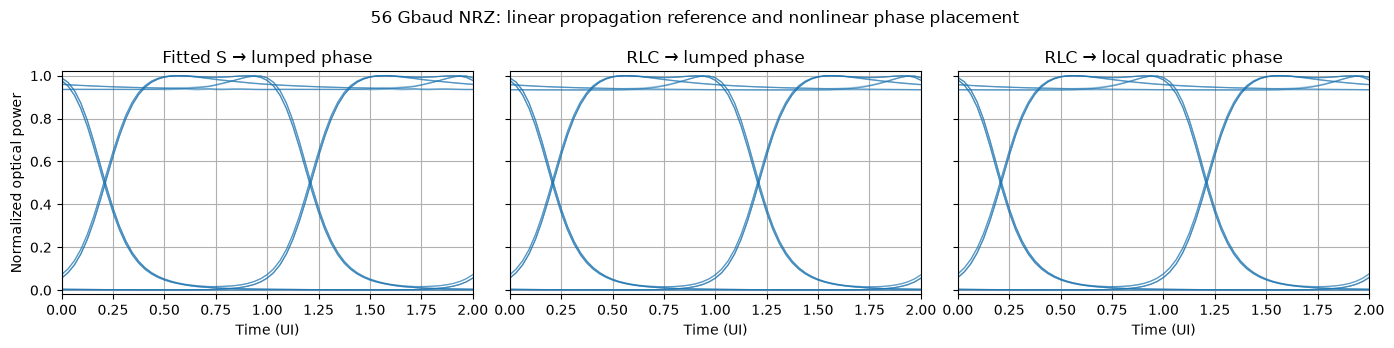

In [11]:
phase_fit = length_mm * (phase_a1 * (v_integrated_fit - v_bias) + phase_a2 * (v_integrated_fit**2 - v_bias**2))
phase_lumped_direct = length_mm * (phase_a1 * (v_integrated_direct - v_bias) + phase_a2 * (v_integrated_direct**2 - v_bias**2))
phase_distributed = (
    dz * 1e3 * np.sum(phase_a1 * (retarded_junction - v_bias) + phase_a2 * (retarded_junction**2 - v_bias**2), axis=1)
)
variance_phase = length_mm * phase_a2 * np.var(retarded_junction, axis=1)
np.testing.assert_allclose(phase_distributed - phase_lumped_direct, variance_phase, atol=1e-12)
print(f"Peak local-vs-lumped quadratic phase difference: {np.max(abs(variance_phase[settled])):.4f} rad")
powers = [(1 + np.sin(phi)) / 2 for phi in (phase_fit, phase_lumped_direct, phase_distributed)]
eye_ui = np.arange(2 * samples_per_ui + 1) / samples_per_ui
fold_bits = np.arange(preamble_bits + 8, len(bits) - 5)
# Only remove the common physical flight time, keeping walk-off and electrical distortion.
query = (fold_bits[:, None] + eye_ui[None, :]) * ui + length_m * n_opt / c
assert query.max() < float(sample_times[-1])
fig, axes = plt.subplots(1, 3, figsize=(14, 3.5), sharex=True, sharey=True)
for ax, power, title in zip(
    axes, powers, ("Fitted S → lumped phase", "RLC → lumped phase", "RLC → local quadratic phase"), strict=True
):
    traces = np.interp(query.ravel(), np.asarray(sample_times), power).reshape(query.shape)
    ax.plot(eye_ui, traces.T, color="C0", alpha=0.15, lw=0.8)
    ax.set(xlabel="Time (UI)", title=title, xlim=(0, 2), ylim=(-0.02, 1.02))
axes[0].set_ylabel("Normalized optical power")
fig.suptitle("56 Gbaud NRZ: linear propagation reference and nonlinear phase placement")
plt.tight_layout()
plt.show()

The finite-record eyes compare the two linear propagation models and the placement of the nonlinear phase law. The parameters are illustrative, not a calibrated PDK model.

Reusable Touchstone, vector-fit and RLGC/Foster data are saved in `data/`.

## 6. Differential line driving both MZM arms

For a symmetric coupled pair, differential and common modes propagate independently, with their own $\gamma_d,Z_d$ and $\gamma_c,Z_c$. We use **full differential/common impedances**, not per-conductor odd/even impedances:

$$V_d=V_a-V_b,\quad I_d=(I_a-I_b)/2,\qquad
V_c=(V_a+V_b)/2,\quad I_c=I_a+I_b.$$

Thus $V_a=V_c+V_d/2$ and $V_b=V_c-V_d/2$, and power is preserved: $V_aI_a+V_bI_b=V_dI_d+V_cI_c$. For per-conductor odd/even data, use $Z_d=2Z_\mathrm{odd}$ and $Z_c=Z_\mathrm{even}/2$; the propagation constants are unchanged. These are also the [scikit-rf mixed-mode conventions](https://scikit-rf.readthedocs.io/en/latest/api/generated/skrf.network.Network.se2gmm.html).

Each conductor drives an identical junction on one arm. Two separate 30 Ω source/load resistors and the junctions become:

| Quantity | Differential mode | Common mode |
| --- | --- | --- |
| Source/load resistance | 60 Ω | 15 Ω |
| Junction series resistance | $2R_j$ | $R_j/2$ |
| Junction capacitance | $C_j/2$ | $2C_j$ |
| Source voltage | $V_{s,a}-V_{s,b}$ | $(V_{s,a}+V_{s,b})/2$ |

Below, illustrative modal data reuse the earlier dispersion with different speeds and impedances. The identities $Z'_m=\gamma_mZ_m$ and $Y'_m=\gamma_m/Z_m$ let us reuse the passive RLC factory. This conversion is algebraic; the RLC fitting and spatial approximation remain the same as before. Identical linear electrical junctions preserve modal independence; asymmetry or voltage-dependent capacitance would require a coupled conductor-domain circuit.

Differential mode: maximum integrated-voltage magnitude error 0.059 dB
Common mode: maximum integrated-voltage magnitude error 0.059 dB


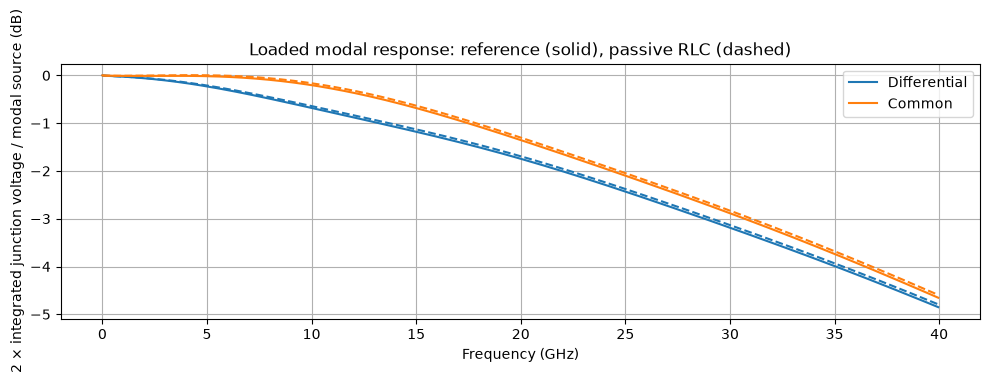

In [12]:
from skrf.media import DefinedGammaZ0


def line_from_mode(gamma_mode, z_mode):
    z_per_m_mode = gamma_mode * z_mode
    y_per_m_mode = gamma_mode / z_mode
    # At DC, only R and G enter Z' and Y'; L/C values here are placeholders.
    l_mode = np.divide(z_per_m_mode.imag, omega, out=np.zeros_like(omega), where=omega > 0)
    c_mode = np.divide(y_per_m_mode.imag, omega, out=np.zeros_like(omega), where=omega > 0)
    return rlgc_transmission_line(frequencies, R=z_per_m_mode.real, L=l_mode, G=y_per_m_mode.real, C=c_mode, poles=foster_poles)


# Replace these arrays with extracted modal data: gamma in 1/m, impedance in ohms.
gamma_d, z_d = 1.05 * gamma, 110.0
gamma_c, z_c = 0.95 * gamma, 35.0
line_d, line_c = line_from_mode(gamma_d, z_d), line_from_mode(gamma_c, z_c)


def loaded_mode(line_mode, scale, bias):
    net = rlc_netlist(
        n_sections=n_sections,
        dz=dz,
        z_ref=scale * z_ref,
        rj_product=scale * rj_product,
        cj_per_m=cj_per_m / scale,
        v_bias=bias,
    )
    models = {"R": Resistor, "C": Capacitor, "drive": WaveformVoltageSource, "line": line_mode(length=dz / 2)}
    return net, models


# Compute Vd/Vsd and Vc/Vsc before reconstructing conductor voltages.
fig, ax = plt.subplots()
for gamma_mode, z_mode, line_mode, scale, label in (
    (gamma_d, z_d, line_d, 2.0, "Differential"),
    (gamma_c, z_c, line_c, 0.5, "Common"),
):
    modal_medium = DefinedGammaZ0(frequency=medium.frequency, gamma=gamma_mode, z0=z_mode, z0_port=scale * z_ref)
    kwargs = {"z_ref": scale * z_ref, "rj_product": scale * rj_product, "cj_per_m": cj_per_m / scale}
    h_reference = h_local(modal_medium.line(d=dz / 2, unit="m").a, **kwargs)[1]
    h_rlc = h_local(direct_half_line(line=line_mode), **kwargs)[1]
    color = "C0" if scale == 2 else "C1"
    ax.plot(frequencies[original_band] / 1e9, 20 * np.log10(abs(2 * h_reference[original_band])), color=color, label=label)
    ax.plot(frequencies[original_band] / 1e9, 20 * np.log10(abs(2 * h_rlc[original_band])), "--", color=color)
    error_db = np.max(abs(20 * np.log10(abs(h_rlc[original_band] / h_reference[original_band]))))
    print(f"{label} mode: maximum integrated-voltage magnitude error {error_db:.3f} dB")
    assert error_db < 0.15
ax.set(
    xlabel="Frequency (GHz)",
    ylabel="2 x integrated junction voltage / modal source (dB)",
    title="Loaded modal response: reference (solid), passive RLC (dashed)",
)
ax.legend()
plt.tight_layout()
plt.show()

### Push-pull eye at 56 Gbaud

Reuse the NRZ pattern with a **4 Vpp differential source**: each conductor has a 2 Vpp source swing about its common bias. Simulate the differential circuit in time. For the common circuit, calculate DC and the steady-state response to a 0.2 Vpp, 10 GHz common-source ripple; linear superposition avoids a second transient solve.

Recover both arm voltages at each junction and apply the same optical delays and quadratic phase law as section 5. At quadrature, $P/P_\mathrm{through}=[1+\sin(\phi_a-\phi_b)]/2$. Locally,

$$f(V_a)-f(V_b)=[a_1+2a_2V_c]V_d.$$

Equal common-mode phase cancels between matched arms. With quadratic phase, however, common voltage changes the differential modulation slope. Compare constant common bias with the added ripple. The common ripple is assumed to have reached periodic steady state before the record starts.

Common-ripple peak change in normalized optical power: 0.0047


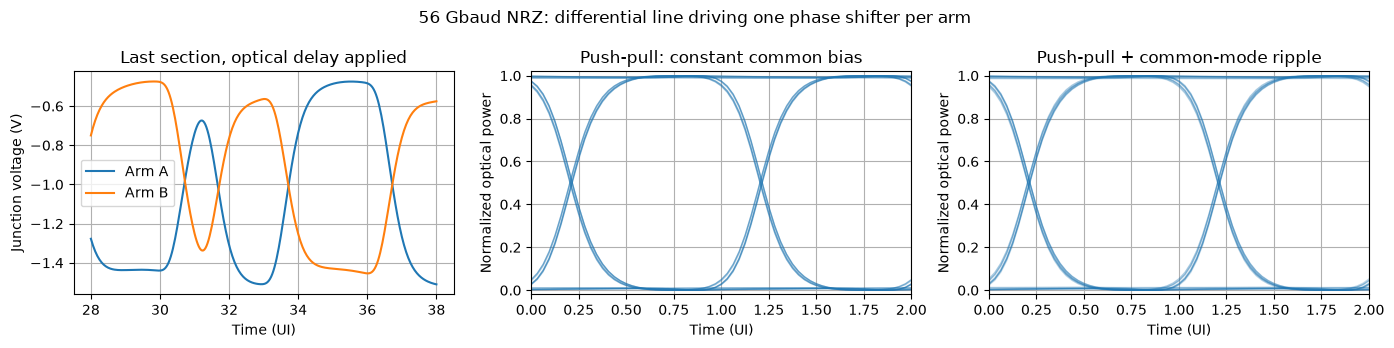

In [13]:
net_d, models_d = loaded_mode(line_d, scale=2.0, bias=0.0)
net_d["instances"]["VS"]["settings"] = {"kind": WAVE_PWL, "pwl_t": jnp.asarray(pwl_t), "pwl_v": jnp.asarray(pwl_v) - 2 * v_bias}
differential = compile_circuit(net_d, models_d, is_complex=False, g_leak=0)
# Check the native modal circuit against its RLC ABCD response before the transient.
ac_d = differential.ac_response(freqs=jnp.asarray(frequencies[ac_indices]), sources={"VS": 1.0})
vj_d_ac = np.stack([np.asarray(differential.port(ac_d["solution"], f"junction_{k}")) for k in range(n_sections)], axis=1)
expected_d = h_local(direct_half_line(line=line_d), z_ref=2 * z_ref, rj_product=2 * rj_product, cj_per_m=cj_per_m / 2)[2]
np.testing.assert_allclose(vj_d_ac, expected_d[ac_indices], atol=1e-8, rtol=1e-7)
sol_d = simulate(differential)
vj_d = np.stack([np.asarray(differential.port(sol_d.ys, f"junction_{k}")) for k in range(n_sections)], axis=1)
vd_retarded = np.column_stack(
    [np.interp(np.asarray(sample_times) - delay, np.asarray(sample_times), vj_d[:, k]) for k, delay in enumerate(monitor_delays)]
)

net_c, models_c = loaded_mode(line_c, scale=0.5, bias=v_bias)
common = compile_circuit(net_c, models_c, is_complex=False, g_leak=0)
f_common, common_source_amplitude = 10e9, 0.1  # 0.2 Vpp at both physical sources.
ac_c = common.ac_response(freqs=jnp.array([f_common]), sources={"VS": common_source_amplitude})
vc_dc = np.array([float(common.port(ac_c["y_dc"], f"junction_{k}")) for k in range(n_sections)])
vc_ac = np.array([complex(common.port(ac_c["solution"], f"junction_{k}")[0]) for k in range(n_sections)])
vc_retarded = vc_dc + np.real(vc_ac * np.exp(2j * np.pi * f_common * (np.asarray(sample_times)[:, None] - monitor_delays)))
va, vb = vc_retarded + vd_retarded / 2, vc_retarded - vd_retarded / 2
np.testing.assert_allclose(va - vb, vd_retarded, atol=1e-12)
np.testing.assert_allclose((va + vb) / 2, vc_retarded, atol=1e-12)


def arm_phase(voltage):
    return dz * 1e3 * np.sum(phase_a1 * (voltage - v_bias) + phase_a2 * (voltage**2 - v_bias**2), axis=1)


delta_phase = arm_phase(va) - arm_phase(vb)
np.testing.assert_allclose(
    delta_phase, dz * 1e3 * np.sum((phase_a1 + 2 * phase_a2 * vc_retarded) * vd_retarded, axis=1), atol=1e-12
)
delta_phase_dc = dz * 1e3 * np.sum((phase_a1 + 2 * phase_a2 * vc_dc) * vd_retarded, axis=1)
power_balanced, power_common = (1 + np.sin(delta_phase_dc)) / 2, (1 + np.sin(delta_phase)) / 2
print(f"Common-ripple peak change in normalized optical power: {np.max(abs(power_common[settled] - power_balanced[settled])):.4f}")

fig, axes = plt.subplots(1, 3, figsize=(14, 3.5))
axes[0].plot(np.asarray(sample_times)[mask] / ui, va[mask, -1], label="Arm A")
axes[0].plot(np.asarray(sample_times)[mask] / ui, vb[mask, -1], label="Arm B")
axes[0].set(xlabel="Time (UI)", ylabel="Junction voltage (V)", title="Last section, optical delay applied")
axes[0].legend()
for ax, power, title in zip(
    axes[1:], (power_balanced, power_common), ("Push-pull: constant common bias", "Push-pull + common-mode ripple"), strict=True
):
    traces = np.interp(query.ravel(), np.asarray(sample_times), power).reshape(query.shape)
    ax.plot(eye_ui, traces.T, color="C0", alpha=0.15, lw=0.8)
    ax.set(xlabel="Time (UI)", ylabel="Normalized optical power", title=title, xlim=(0, 2), ylim=(-0.02, 1.02))
fig.suptitle("56 Gbaud NRZ: differential line driving one phase shifter per arm")
plt.tight_layout()
plt.show()